In [25]:
import numpy as np

import cec2017.functions as cec
import cec2017.utils as utils

In [26]:
BOTTOM_BORDER = -100
TOP_BORDER = 100
DIM = 10

In [28]:
class Particle:
    def __init__(self, dim, f, w, c1, c2):
        self.f = f
        self.w = w
        self.c1 = c1
        self.c2 = c2
        self.velocity_limit = 0.1 * (TOP_BORDER - BOTTOM_BORDER)
        self.x = np.random.uniform(BOTTOM_BORDER, TOP_BORDER, dim)
        self.v = np.random.uniform(-self.velocity_limit, self.velocity_limit, dim)
        self.p = self.x.copy()
        self.best_value = float(f(self.p[None, :])[0])

    def step(self, g):
        rp = np.random.uniform(0, 1, self.x.size)
        rg = np.random.uniform(0, 1, self.x.size)
        self.v = self.w * self.v + self.c1 * rp * (self.p - self.x) + self.c2 * rg * (g - self.x)
        self.v = np.clip(self.v, -self.velocity_limit, self.velocity_limit)
        self.x = np.clip(self.x + self.v, BOTTOM_BORDER, TOP_BORDER)
        value = float(self.f(self.x[None, :])[0])
        if value < self.best_value:
            self.best_value = value
            self.p = self.x.copy()
        return self.best_value, self.p

class Swarm:
    def __init__(self, cnt, dim, f, w, c1, c2):
        self.swarm = [Particle(dim, f, w, c1, c2) for _ in range(cnt)]
        best = min(self.swarm, key=lambda particle: particle.best_value)
        self.g = best.p.copy()
        self.best_val = best.best_value
    
    def step(self):
        for particle in self.swarm:
            cur_val, cur = particle.step(self.g)
            if cur_val < self.best_val:
                self.best_val = cur_val
                self.g = cur.copy()
    
    def run(self, iterations):
        for _ in range(iterations):
            self.step()
        return self.best_val, self.g

f1: value=126.28399077733462, error=26.283990777334623


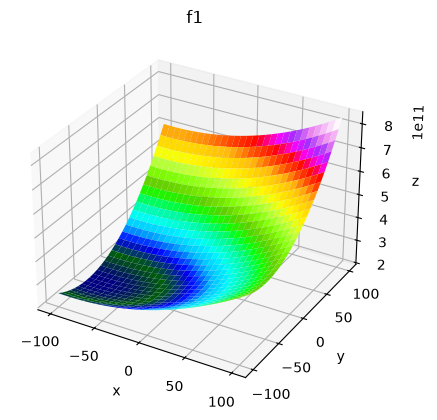

f3: value=300.0, error=0.0


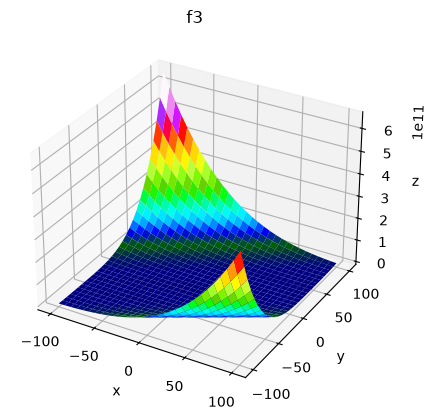

f4: value=408.30336458150686, error=8.303364581506855


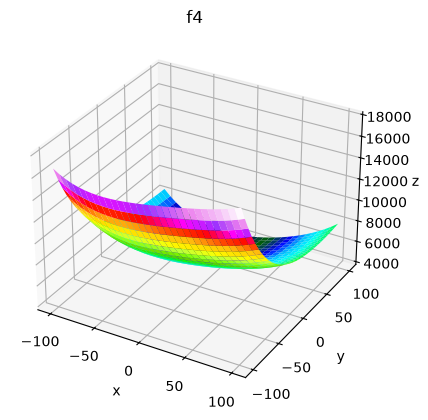

f5: value=531.8385990099275, error=31.83859900992752


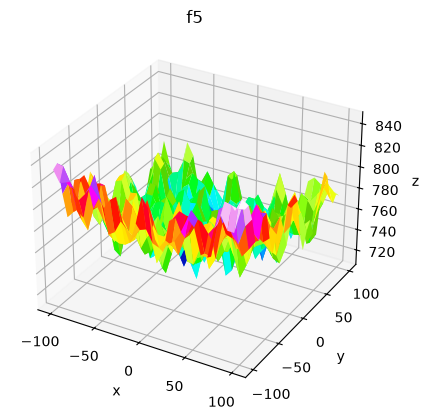

f6: value=600.153590496351, error=0.1535904963509438


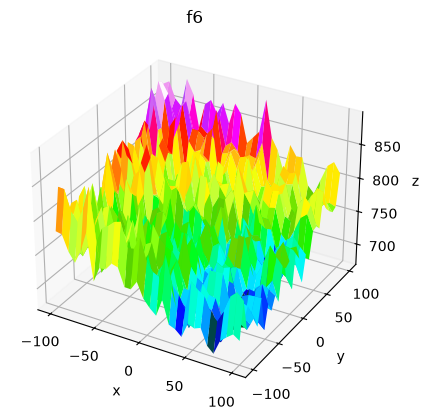

f7: value=718.9219293976535, error=18.921929397653457


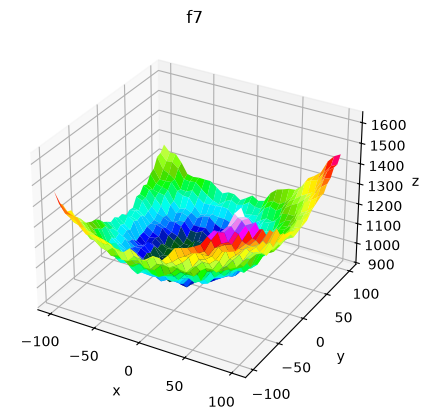

f8: value=810.9445445902071, error=10.944544590207101


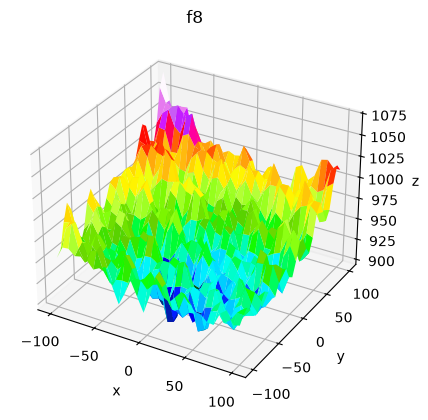

f9: value=900.0, error=0.0


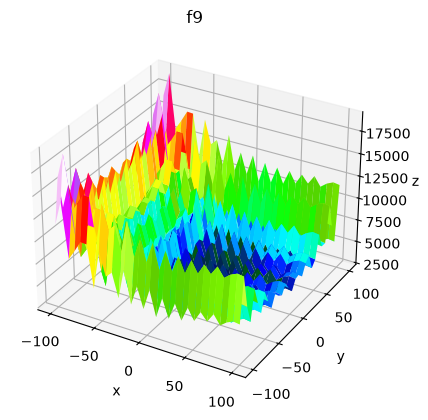

f10: value=1895.0008171695636, error=895.0008171695636


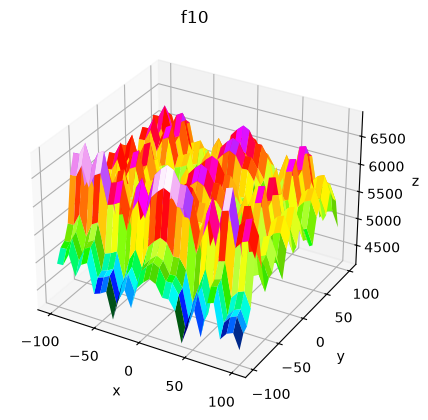

f11: value=1130.5651917594848, error=30.565191759484833


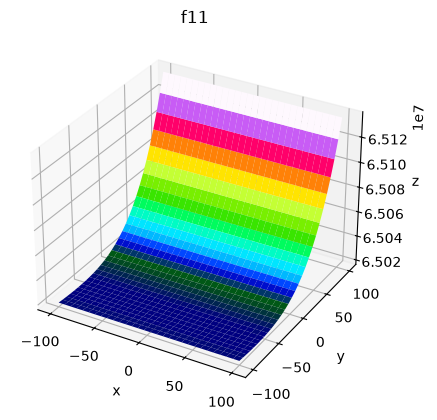

f12: value=17601.408133832676, error=16401.408133832676


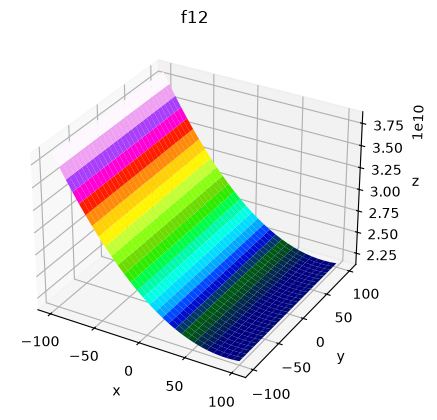

f13: value=2198.864033928233, error=898.8640339282329


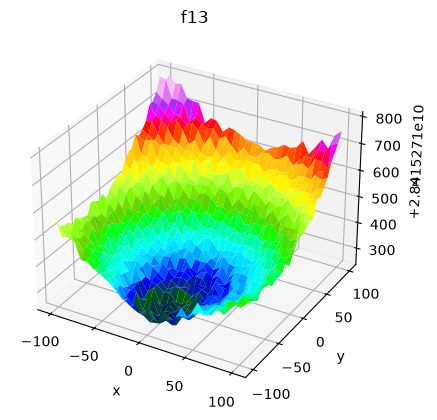

f14: value=1666.0266774300635, error=266.0266774300635


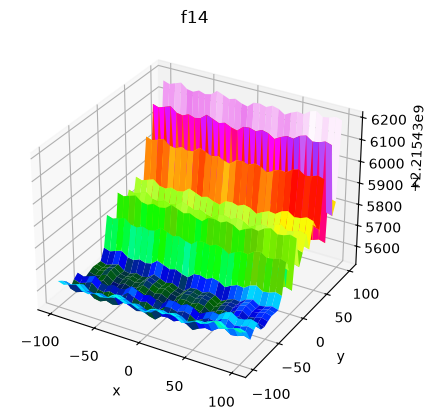

f15: value=1760.9551721021576, error=260.9551721021576


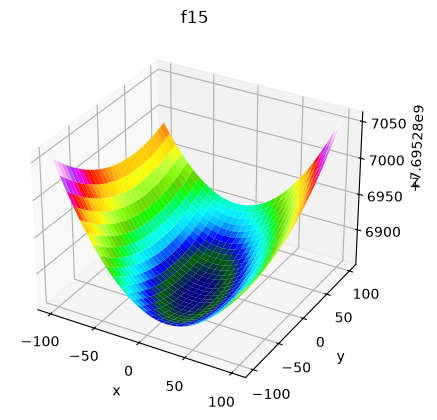

f16: value=1740.2832393910346, error=140.2832393910346


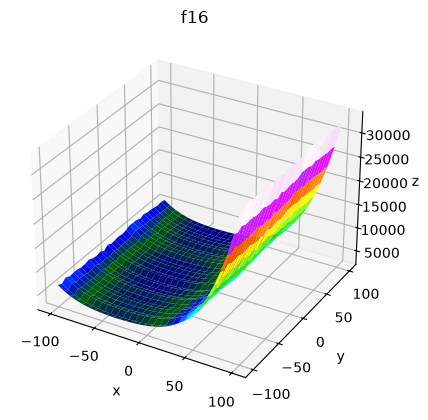

f17: value=1744.239371022271, error=44.239371022270916


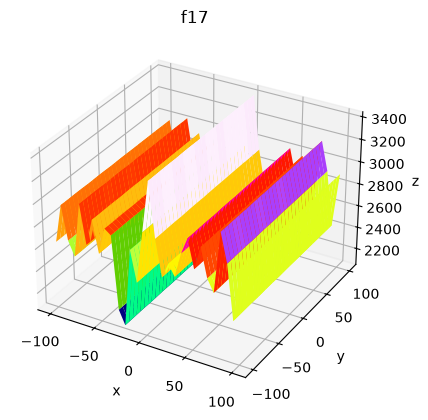

f18: value=6497.875544385453, error=4697.875544385453


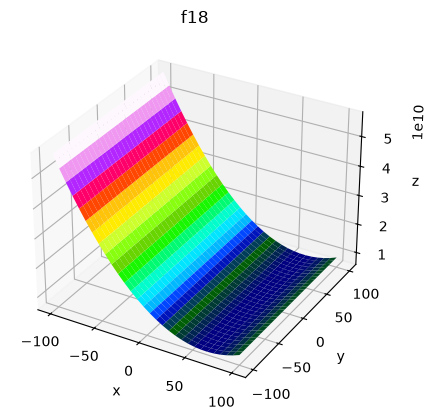

f19: value=5218.350186694117, error=3318.350186694117


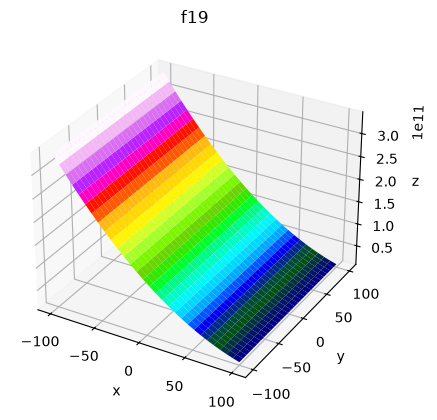

f20: value=2157.616679382976, error=157.61667938297614


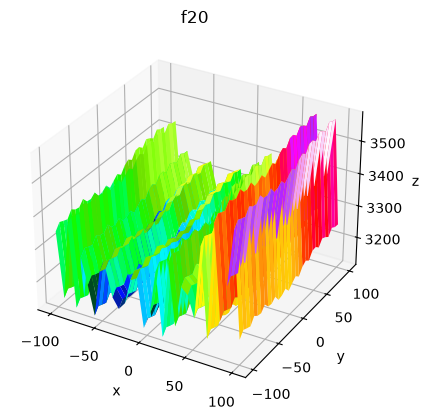

f21: value=2316.4223644992117, error=216.42236449921165


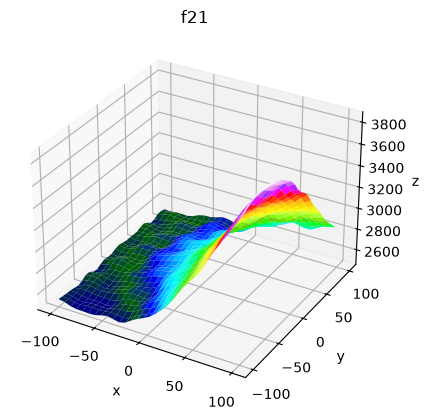

f22: value=2217.5207252434875, error=17.520725243487504


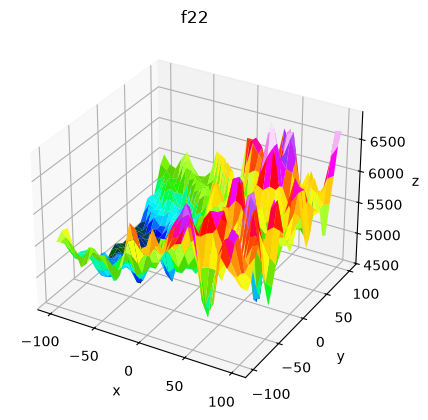

f23: value=2621.130101054974, error=321.13010105497415


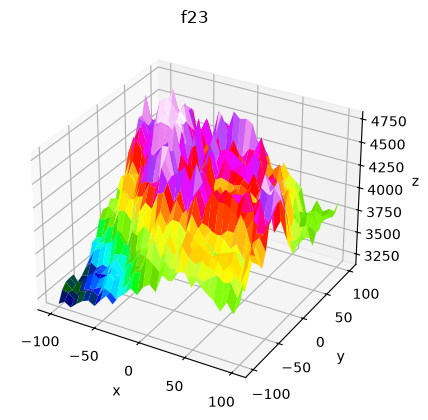

f24: value=2500.0000000000005, error=100.00000000000045


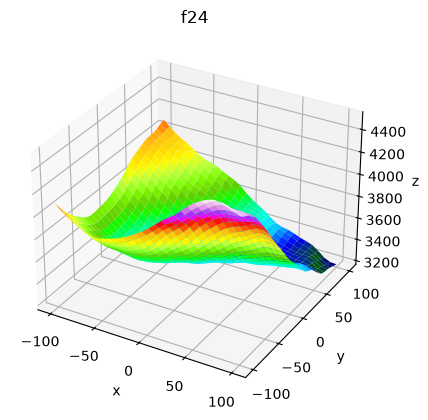

f25: value=2943.554666345385, error=443.55466634538516


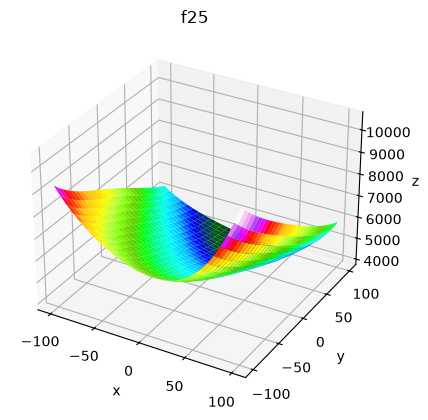

f26: value=2900.0000000000005, error=300.00000000000045


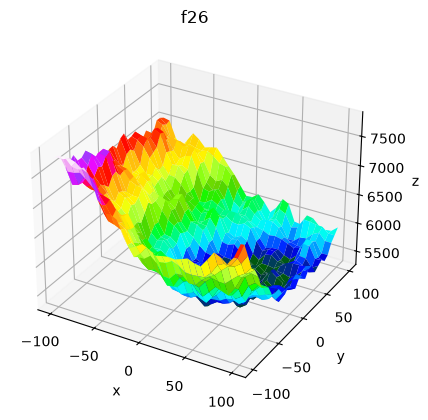

f27: value=3102.2979512272614, error=402.29795122726136


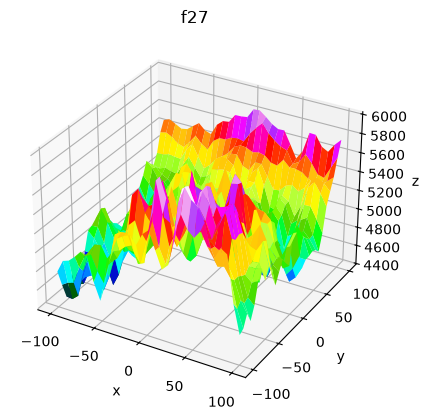

f28: value=3383.7546815342157, error=583.7546815342157


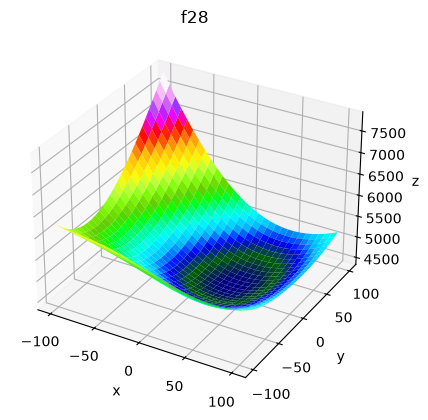

f29: value=3156.279491642829, error=256.2794916428288


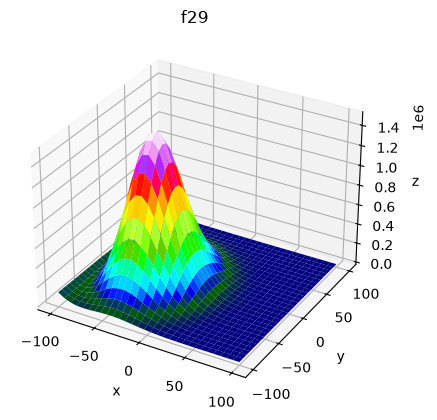

f30: value=9351.622944417737, error=6351.622944417737


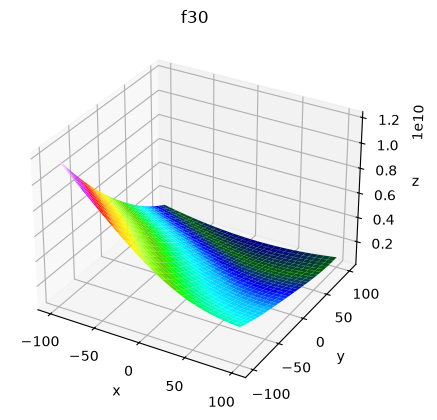

In [29]:
for i in range(len(cec.all_functions)):
    f = cec.all_functions[i]
    if f is cec.f2:
        continue
    s = Swarm(200, DIM, f, 0.7, 1, 1)
    val, cord = s.run(500)
    optimum = 100 * (i + 1)
    print(f"f{i + 1}: value={val:}, error={val - optimum}")
    utils.surface_plot(f, dimension=DIM)